# 1- Assessing if Occupancy Data is Feasable

#### **Current Engineering Problem Idea:**
Can we use past room occupancy to predict room occupancy 30min in advance, which can possibly be applied to HVAC/ventilation systems 

#### **Key assessments:**
1. Which monitored spaces have enough data and variation in headcount?
2. How does headcount change over time?
3. How long are the gaps between recorded observations?
4. How many 30min intervals can we evaluate using recent measured values?



In [12]:
#Import Libraries
from pathlib import Path
import zipfile

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("pandas version:", pd.__version__)


pandas version: 3.0.6


### Checking the Data Set is where it should be

In [13]:
# Finding and validating the dataset
# Check the folder our notebook is running from
print(Path.cwd())

# Location of the dataset
zip_path = Path("../data/DataSet2.zip")

# Name of the occupancy CSV inside the ZIP
csv_name = ("DataSet2_Env_and_Occupancy/"
            "5occupancySensor_MayToDec2024_9MRows/"
            "5occupancySensor_MayToDec2024_9MRows.csv")

print("ZIP found:", zip_path.exists())

c:\Users\chris\OneDrive\Desktop\MMA3001\Project\mma3001_project\notebooks
ZIP found: True


### Filtering Data for only October & assessing any invalid timestamps or headcounts

In [14]:
# Columns we want from the CSV
columns = ["floorspaceid", "collecteddate",
           "headcount", "occupancystatus"]

# Empty list to store October data
october_parts = []

# Open the CSV inside the ZIP
with zipfile.ZipFile(zip_path) as zip_file:
    with zip_file.open(csv_name) as csv_file:

        # Read 200,000 rows at a time
        for chunk in pd.read_csv(csv_file, usecols=columns,
                                 chunksize=200000):

            # Keep only October 2024 records
            october_rows = chunk[
                chunk["collecteddate"].str.startswith("2024-10-", na=False)
            ]

            october_parts.append(october_rows)

# Combine all October records into one table
october = pd.concat(october_parts, ignore_index=True)

# Convert timestamps and headcounts to useful data types
october["timestamp"] = pd.to_datetime(
    october["collecteddate"], utc=True, errors="coerce"
)

october["local_time"] = october["timestamp"].dt.tz_convert(
    "Australia/Melbourne"
)

october["headcount"] = pd.to_numeric(
    october["headcount"], errors="coerce"
)

# Display basic information
print("October records:", len(october))
print("Building spaces:", october["floorspaceid"].nunique())
print("Invalid timestamps:", october["timestamp"].isna().sum())
print("Invalid headcounts:", october["headcount"].isna().sum())

October records: 705592
Building spaces: 5
Invalid timestamps: 0
Invalid headcounts: 0


### Comparing each floorspace to see which is better suited for the model

In [15]:
# Empty list to store information about each space
space_rows = []

# Go through each building space
for space_id in october["floorspaceid"].unique():

    # Select only the rows belonging to this space
    space_data = october[october["floorspaceid"] == space_id]

    # Calculate and store information about this space
    space_rows.append({
        "floorspaceid": space_id,
        "space": space_id[:8],
        "records": len(space_data),
        "first_record": space_data["local_time"].min(),
        "last_record": space_data["local_time"].max(),
        "minimum_people": space_data["headcount"].min(),
        "maximum_people": space_data["headcount"].max(),
        "distinct_headcounts": space_data["headcount"].nunique()
    })

# Convert the list into a table
space_summary = pd.DataFrame(space_rows)

# Display the important columns
display(space_summary[[
    "space", "records", "first_record", "last_record",
    "minimum_people", "maximum_people", "distinct_headcounts"
]])

,space,records,first_record,last_record,minimum_people,maximum_people,distinct_headcounts
0,cca1ac3e,142632,2024-10-01 00:00:10+10:00,2024-10-31 23:58:28+11:00,0,52,51
1,227f1068,134288,2024-10-01 00:06:14+10:00,2024-10-31 23:55:00+11:00,0,30,31
2,941f0352,104549,2024-10-01 00:13:10+10:00,2024-10-31 23:59:46+11:00,0,12,12
3,3e5a14df,220854,2024-10-01 00:21:48+10:00,2024-10-31 23:54:18+11:00,0,21,22
4,0f3f37f8,103269,2024-10-01 00:26:14+10:00,2024-10-31 23:50:58+11:00,0,17,18


### Assessing each spaces time gaps

In [ ]:
# Sort the data by building space and measurement time
october = october.sort_values(
    ["floorspaceid", "timestamp"]
).copy()

# Empty list to store the results
gap_rows = []

# Examine each building space separately
for space_id in october["floorspaceid"].unique():

    # Select measurements for this space
    space_data = october[october["floorspaceid"] == space_id]

    # Calculate time between consecutive measurements
    gaps = space_data["timestamp"].diff()

    # Convert time differences into minutes
    gaps_minutes = gaps.dt.total_seconds() / 60

    # Store the results
    gap_rows.append({
        "space": space_id[:8],
        "median_gap_minutes": gaps_minutes.median(),
        "longest_gap_minutes": gaps_minutes.max(),
        "gaps_over_30_minutes": (gaps_minutes > 30).sum()
    })

# Convert results into a table
gap_summary = pd.DataFrame(gap_rows)

# Check whether timestamps are repeated within a space
duplicate_times = october.duplicated(
    subset=["floorspaceid", "timestamp"]
).sum()

print("Repeated timestamps:", duplicate_times)

# Display the gap statistics
display(gap_summary.round(2))

Repeated timestamps: 0


,space,median_gap_minutes,longest_gap_minutes,gaps_over_30_minutes
0,0f3f37f8,0.07,534.10,163
1,227f1068,0.07,785.97,101
2,3e5a14df,0.03,638.63,148
3,941f0352,0.07,603.17,181
4,cca1ac3e,0.03,1320.87,129


### Displaying heacount of the most frequently recorded space in October (Space 2 - e85a14df)

Example space: 3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8
Measurements on example day: 8404


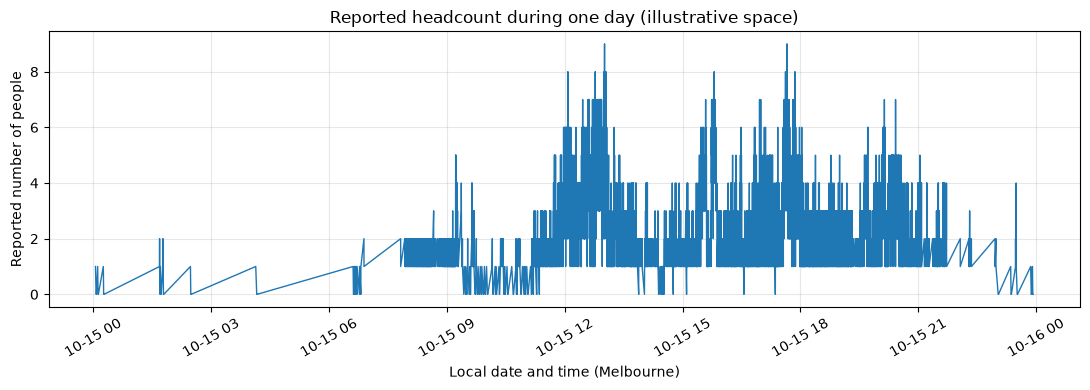

In [17]:
# Display example only: the most frequently recorded space in October.
example_space = space_summary.sort_values("records", ascending=False).iloc[0]["floorspaceid"]
example_date = pd.Timestamp("2024-10-15").date()

example = october[
    (october["floorspaceid"] == example_space)
    & (october["local_time"].dt.date == example_date)
]

print("Example space:", example_space)
print("Measurements on example day:", len(example))

plt.figure(figsize=(11, 4))
plt.plot(example["local_time"], example["headcount"], linewidth=1)
plt.title("Reported headcount during one day (illustrative space)")
plt.xlabel("Local date and time (Melbourne)")
plt.ylabel("Reported number of people")
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Determining the number of 30min forecasts 
- By segmenting the month of october into 15min intervals we can find the number of scheduled forecast opportunities
- Note: The segments arent filtered, its purely the number of useable segments excluding the time lost due to daylight savings

### General rules (Idea):
1. The prediction target is 30min ahead of time
2. We will make a 30min prediction every 15min
3. A measurement accepted/used only if it was recorded in the preceding five minutes
4. We never use a measurement from after the forecast starting time as an input



In [18]:
# Trial settings for our prediction problem
horizon = pd.Timedelta(minutes=30)
max_age = pd.Timedelta(minutes=5)

# Create prediction starting times every 15 minutes
start_times = pd.date_range(
    "2024-10-01",
    "2024-11-01",
    freq="15min",
    tz="Australia/Melbourne",
    inclusive="left"
)

# Only include predictions that finish within October
end_of_month = pd.Timestamp(
    "2024-11-01", tz="Australia/Melbourne"
)

start_times = start_times[
    start_times + horizon < end_of_month
]

# Determine the future time for each prediction
target_times = start_times + horizon

print("Scheduled predictions:", len(start_times))
print("First starting time:", start_times[0])
print("First target time:", target_times[0])

Scheduled predictions: 2970
First starting time: 2024-10-01 00:00:00+10:00
First target time: 2024-10-01 00:30:00+10:00


### Then we can filter the data into usable time period for each floor space   

In [ ]:
# Store the results for each building space
results = []

for space_id in october["floorspaceid"].unique():

    # Select the measurements for this space
    space_data = october[
        october["floorspaceid"] == space_id
    ]

    # Use timestamps to organise the headcount readings
    readings = space_data.set_index("local_time")[
        "headcount"
    ].sort_index()

    # Find the most recent reading at each starting time
    start_counts = readings.reindex(
        start_times,
        method="ffill",
        tolerance=max_age
    )

    # Find the most recent reading at each target time
    future_counts = readings.reindex(
        target_times,
        method="ffill",
        tolerance=max_age
    )

    # Put starting and future counts alongside each other
    pairs = pd.DataFrame({
        "start_count": start_counts.to_numpy(),
        "target_count": future_counts.to_numpy()
    })

    # Keep only examples with both measurements
    usable = pairs.dropna()

    # Calculate useful statistics
    results.append({
        "space": space_id[:8],
        "usable_pairs": len(usable),
        "usable_percent": 100 * len(usable) / len(start_times),
        "headcount_changed_percent": 100 * (
            usable["start_count"] != usable["target_count"]
        ).mean(),
        "mean_change_in_people": (
            usable["start_count"] - usable["target_count"]
        ).abs().mean()
    })

# Create the summary table
feasibility = pd.DataFrame(results)

display(feasibility.round(2))

,space,usable_pairs,usable_percent,headcount_changed_percent,mean_change_in_people
0,0f3f37f8,1477,49.73,52.47,0.78
1,227f1068,1585,53.37,68.83,1.62
2,3e5a14df,1592,53.60,64.32,1.26
3,941f0352,1459,49.12,55.31,0.78
4,cca1ac3e,1271,42.79,77.03,2.16
